# MyMart Fraud Detection — Section A: Model Development
## The Financial Shield — an out-of-time, leakage-safe MLP for chargeback triage

**Business context.** MyMart loses **RM 85** for every transaction that ends in a chargeback. Chargebacks represent only about 3% of roughly 42,000 transactions, so a model that predicts every order as legitimate can appear ~97% accurate while protecting **RM 0**. This notebook builds a compact Multi-Layer Perceptron (MLP) that produces a **risk ranking** for a human review queue.

**What makes this workflow production-minded**

| Guardrail | How it is implemented | Why it matters |
|---|---|---|
| Future holdout | Chronological 60% / 20% / 20% train / validation / test split | Simulates scoring future transactions rather than random historical rows |
| Causal features | Customer history uses only transactions that happened earlier in time | Prevents future behaviour entering a past decision |
| Fit-on-train preprocessing | Imputation, category vocabulary, scaling, and SMOTENC use training data only | Eliminates preprocessing leakage |
| Honest selection | Candidate strategies are compared on validation PR-AUC only | The test set stays untouched until the final model is selected |
| Operational decisions | F1, recall-target, and fixed-capacity review modes | Connects scores to review capacity and prevented loss |

**Evaluation protocol — no test-set fishing**
1. Sort transactions by event time, then reserve the latest 20% as the final out-of-time test period.
2. Build only target-free, causal history features; no future transaction contributes to an earlier row.
3. Fit all preprocessors and resampling steps on the training period only.
4. Select the training strategy and validation-tuned thresholds without scoring the test period.
5. Score the selected model on the test period once, then report uncertainty and business impact.

> **How to run:** run top-to-bottom (in Colab: *Runtime → Run all*). Keep `mymart_transactions_v1.csv` beside the notebook or upload it to `/content/`. A CPU runtime is sufficient; the model comparison normally takes a few minutes.


### 0. Environment, reproducibility, and decision settings

The install cell is guarded: it installs only missing packages. The configuration cell exposes the business knobs that should be agreed with operations before deployment: the loss per chargeback, desired recall, and daily review capacity.


In [1]:
# Install only what is missing (module name -> pip package name)
import importlib.util
import subprocess
import sys

REQUIRED = {
    "tensorflow": "tensorflow",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "imblearn": "imbalanced-learn",
}

def _module_available(module: str) -> bool:
    try:
        return importlib.util.find_spec(module) is not None
    except (ImportError, ValueError):
        return False

missing = [pkg for module, pkg in REQUIRED.items() if not _module_available(module)]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
else:
    print("All required packages are already installed.")


All required packages are already installed.


In [2]:
import os
import sys
import tempfile
import warnings

# Must be set before importing matplotlib / TensorFlow. Keeping caches in a
# temporary writable location makes the notebook portable to hosted runtimes.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault(
    "MPLCONFIGDIR", os.path.join(tempfile.gettempdir(), "mymart-matplotlib")
)

import imblearn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf
from imblearn.over_sampling import SMOTENC
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import StandardScaler
from sklearn.utils import class_weight
from tensorflow.keras import layers, models

warnings.filterwarnings("ignore", category=FutureWarning)

print(f"Python       : {sys.version.split()[0]}")
print(f"TensorFlow   : {tf.__version__} (Keras {tf.keras.__version__})")
print(f"pandas       : {pd.__version__} | numpy {np.__version__}")
print(f"scikit-learn : {sklearn.__version__} | imbalanced-learn {imblearn.__version__}")


Matplotlib is building the font cache; this may take a moment.


Python       : 3.14.0
TensorFlow   : 2.22.0-rc0 (Keras 3.16.0.dev2026111103)
pandas       : 3.0.5 | numpy 2.5.2
scikit-learn : 1.9.0 | imbalanced-learn 0.14.2


In [3]:
# --------------------------- reproducibility & style -----------------------
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    # Some TensorFlow backends do not expose deterministic kernels.
    pass

# --------------------------- business / experiment settings -----------------
RM_PER_CHARGEBACK = 85          # Direct loss and penalties per missed chargeback
TARGET_RECALL = 0.90            # High-recall operating-mode target
REVIEW_BUDGET_FRACTION = 0.10   # Scenario: operations can review top 10% of orders
N_BOOTSTRAPS = 1_000            # Test PR-AUC uncertainty samples
TRAIN_FRACTION = 0.60
VALIDATION_FRACTION = 0.20
SMOTE_TARGET_RATIO = 0.50       # Minority / majority ratio after SMOTENC

# --------------------------- dataset location --------------------------------
def find_csv(filename="mymart_transactions_v1.csv"):
    """Find the CSV next to the notebook first, then in Colab's /content."""
    for candidate in (filename, os.path.join("/content", filename)):
        if os.path.exists(candidate):
            return candidate
    raise FileNotFoundError(
        f"Could not find '{filename}'. Place it next to the notebook or upload it "
        "to /content/ in Google Colab."
    )


CSV_PATH = find_csv()
print(f"Using dataset: {CSV_PATH}")

# --------------------------- plotting style ----------------------------------
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.dpi": 100,
})
BLUE, RED, GREEN, GREY, PURPLE = "#4A90E2", "#D0021B", "#2ECC71", "#7F8C8D", "#8E44AD"
print("Environment ready.")


Using dataset: mymart_transactions_v1.csv
Environment ready.


### 1. Data loading & initial inspection (A1)

Before modelling, the notebook checks the data contract: required fields, binary labels, unique transaction IDs, valid timestamps, and non-negative business measures. Failing fast here is safer than quietly training on corrupted data.


In [4]:
df = pd.read_csv(CSV_PATH, parse_dates=["txn_date"])

REQUIRED_COLUMNS = {
    "transaction_id", "txn_date", "customer_id", "state",
    "product_category", "order_value_myr", "num_items",
    "payment_method", "is_new_customer", "device_type",
    "account_age_days", "chargeback",
}
missing_columns = REQUIRED_COLUMNS.difference(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")
if df["txn_date"].isna().any():
    raise ValueError("txn_date contains invalid or missing timestamps")
if not df["chargeback"].dropna().isin([0, 1]).all() or df["chargeback"].isna().any():
    raise ValueError("chargeback must contain only binary 0/1 labels with no missing values")
if df["transaction_id"].duplicated().any():
    raise ValueError("transaction_id must be unique")
if (df["order_value_myr"] <= 0).any() or (df["num_items"] <= 0).any():
    raise ValueError("order_value_myr and num_items must be strictly positive")
if (df["account_age_days"].dropna() < 0).any():
    raise ValueError("account_age_days cannot be negative")

display(df.head())

print(f"Rows             : {len(df):,}")
print(f"Columns          : {df.shape[1]}")
print(f"Date range       : {df['txn_date'].min()}  ->  {df['txn_date'].max()}")
print(f"Duplicate txn IDs: {df['transaction_id'].duplicated().sum()}")

class_summary = (
    df["chargeback"].value_counts().sort_index().to_frame("count")
    .assign(share=lambda table: (table["count"] / len(df)).map("{:.2%}".format))
    .rename(index={0: "Legitimate (0)", 1: "Chargeback (1)"})
)
display(class_summary)

df.info()


,transaction_id,txn_date,customer_id,state,product_category,order_value_myr,num_items,payment_method,is_new_customer,device_type,account_age_days,chargeback
0,TXN-00000001,2023-01-01 00:10:17,CUST-14270,Selangor,Electronics,60.91,5,e-Wallet,0,Mobile,620.0,0
1,TXN-00000002,2023-01-01 00:13:34,CUST-08864,Perak,Electronics,365.51,1,e-Wallet,1,Mobile,1134.0,1
2,TXN-00000003,2023-01-01 00:29:15,CUST-15508,Johor,Home & Living,111.97,8,Debit Card,0,Desktop,513.0,0
3,TXN-00000004,2023-01-01 00:53:32,CUST-10270,Selangor,Home & Living,167.20,4,Buy Now Pay Later,0,Mobile,1002.0,0
4,TXN-00000005,2023-01-01 01:08:58,CUST-09889,Selangor,Fashion,58.05,1,Credit Card,1,Mobile,1149.0,0


Rows             : 42,000
Columns          : 12
Date range       : 2023-01-01 00:10:17  ->  2024-06-30 23:16:15
Duplicate txn IDs: 0


,count,share
chargeback,,
Legitimate (0),40738,97.00%
Chargeback (1),1262,3.00%


<class 'pandas.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    42000 non-null  str           
 1   txn_date          42000 non-null  datetime64[us]
 2   customer_id       42000 non-null  str           
 3   state             41580 non-null  str           
 4   product_category  42000 non-null  str           
 5   order_value_myr   42000 non-null  float64       
 6   num_items         42000 non-null  int64         
 7   payment_method    42000 non-null  str           
 8   is_new_customer   42000 non-null  int64         
 9   device_type       42000 non-null  str           
 10  account_age_days  40320 non-null  float64       
 11  chargeback        42000 non-null  int64         
dtypes: datetime64[us](1), float64(2), int64(3), str(6)
memory usage: 3.8 MB


### 2. The analytical deep dive (EDA)

We are not looking for outliers — we are looking for the *digital fingerprint* of a fraudulent transaction: how the classes are balanced, where data is missing, and which features (alone, and **in combination**) carry chargeback signal.


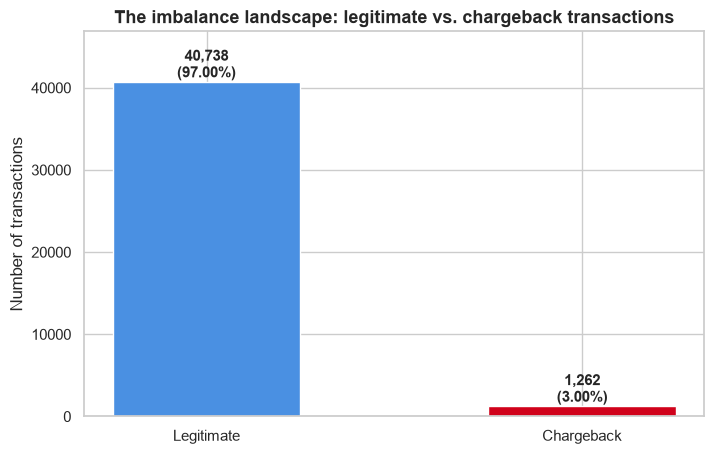

In [5]:
# Visualising the business reality: the "needle in a haystack" problem
class_counts = df["chargeback"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["Legitimate", "Chargeback"], class_counts.values, color=[BLUE, RED], width=0.5)
for bar, count in zip(bars, class_counts.values):
    ax.annotate(
        f"{count:,}\n({count / len(df):.2%})",
        xy=(bar.get_x() + bar.get_width() / 2, count),
        ha="center", va="bottom", fontsize=11, fontweight="bold",
    )
ax.set_ylabel("Number of transactions")
ax.set_title("The imbalance landscape: legitimate vs. chargeback transactions")
ax.margins(y=0.15)  # headroom for the annotations
plt.show()


Missing values per column:


,missing,share
account_age_days,1680,4.0%
state,420,1.0%


chargeback                     0        1
order_value_myr  count  40738.00  1262.00
                 mean     248.47   255.42
                 std      235.31   241.68
                 min        9.90    14.66
                 25%      104.90   105.58
                 50%      181.32   187.16
                 75%      310.29   319.53
                 max     4724.85  2082.08
num_items        count  40738.00  1262.00
                 mean       3.18     3.26
                 std        2.54     2.66
                 min        1.00     1.00
                 25%        1.00     1.00
                 50%        2.00     2.00
                 75%        4.00     4.00
                 max       15.00    15.00
account_age_days count  39116.00  1204.00
                 mean     900.14   897.72
                 std      520.48   515.27
                 min        1.00     1.00
                 25%      446.00   454.25
                 50%      902.00   888.00
                 75%     1354.00  1331.50
                 max     1799.00  1798.00

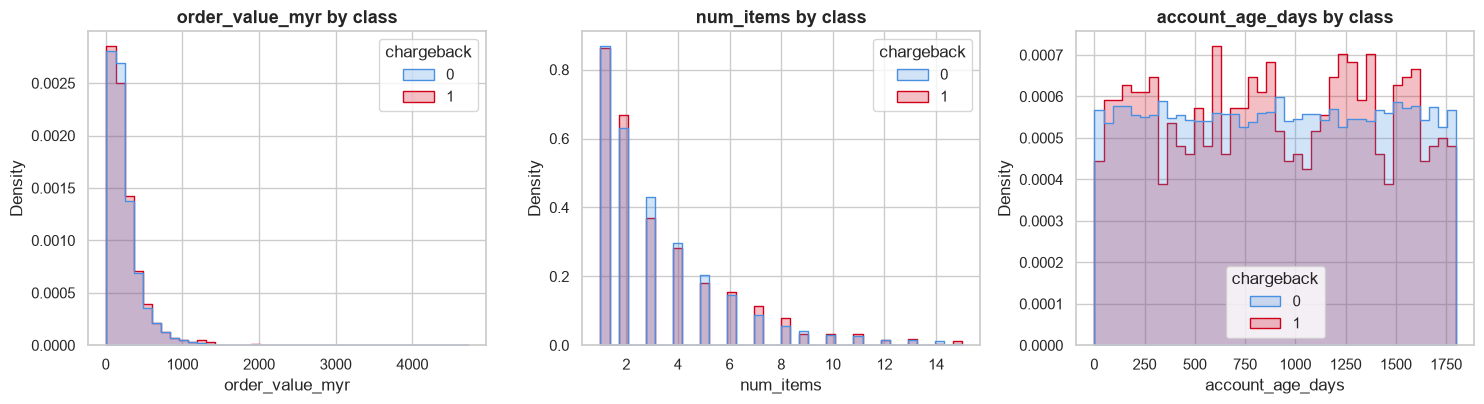

In [6]:
# Missing values, and whether the numeric distributions differ by class
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Missing values per column:")
display(missing.to_frame("missing").assign(share=lambda t: (t["missing"] / len(df)).map("{:.1%}".format)))

NUMERIC_COLS = ["order_value_myr", "num_items", "account_age_days"]
display(df.groupby("chargeback")[NUMERIC_COLS].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.histplot(
        data=df.dropna(subset=[col]), x=col, hue="chargeback",
        element="step", stat="density", common_norm=False, bins=40,
        palette=[BLUE, RED], ax=ax,
    )
    ax.set_title(f"{col} by class")
    ax.get_legend().set_title("chargeback")
fig.tight_layout()
plt.show()


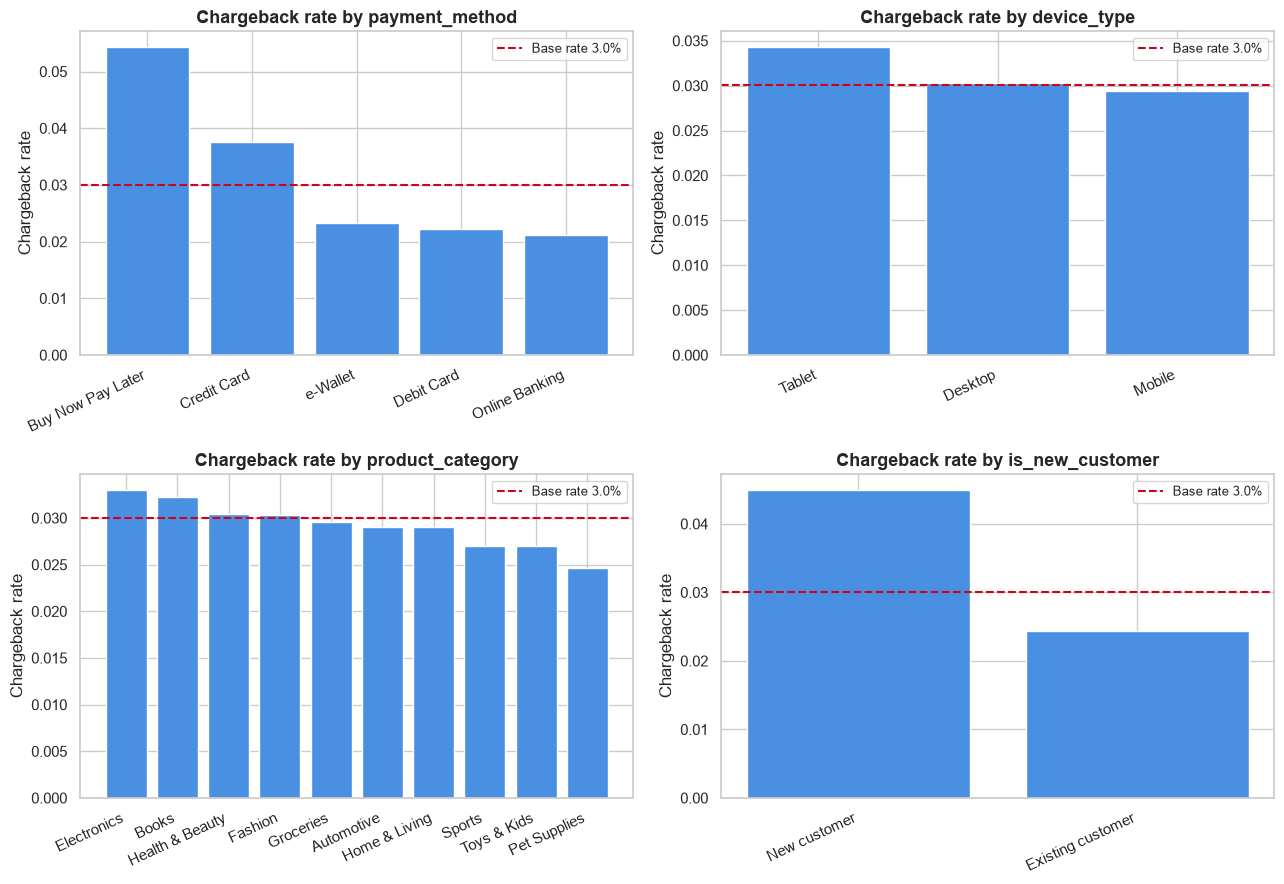

Chargeback rate by state — highest: Sarawak 4.2% | lowest: Negeri Sembilan 2.2%


In [7]:
# Fraud rate across the categorical features (base rate drawn in red)
base_rate = df["chargeback"].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
panels = [
    ("payment_method", axes[0, 0]),
    ("device_type", axes[0, 1]),
    ("product_category", axes[1, 0]),
    ("is_new_customer", axes[1, 1]),
]
for col, ax in panels:
    rates = df.groupby(col)["chargeback"].mean().sort_values(ascending=False)
    ax.bar(range(len(rates)), rates.values, color=BLUE)
    labels = [str(v) for v in rates.index]
    if col == "is_new_customer":
        labels = ["Existing customer" if v == 0 else "New customer" for v in rates.index]
    ax.set_xticks(range(len(rates)))
    ax.set_xticklabels(labels, rotation=25, ha="right")
    ax.axhline(base_rate, color=RED, ls="--", lw=1.5, label=f"Base rate {base_rate:.1%}")
    ax.set_title(f"Chargeback rate by {col}")
    ax.set_ylabel("Chargeback rate")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

state_rates = df.groupby("state")["chargeback"].mean().sort_values(ascending=False)
print(f"Chargeback rate by state — highest: {state_rates.index[0]} {state_rates.iloc[0]:.1%} | "
      f"lowest: {state_rates.index[-1]} {state_rates.iloc[-1]:.1%}")


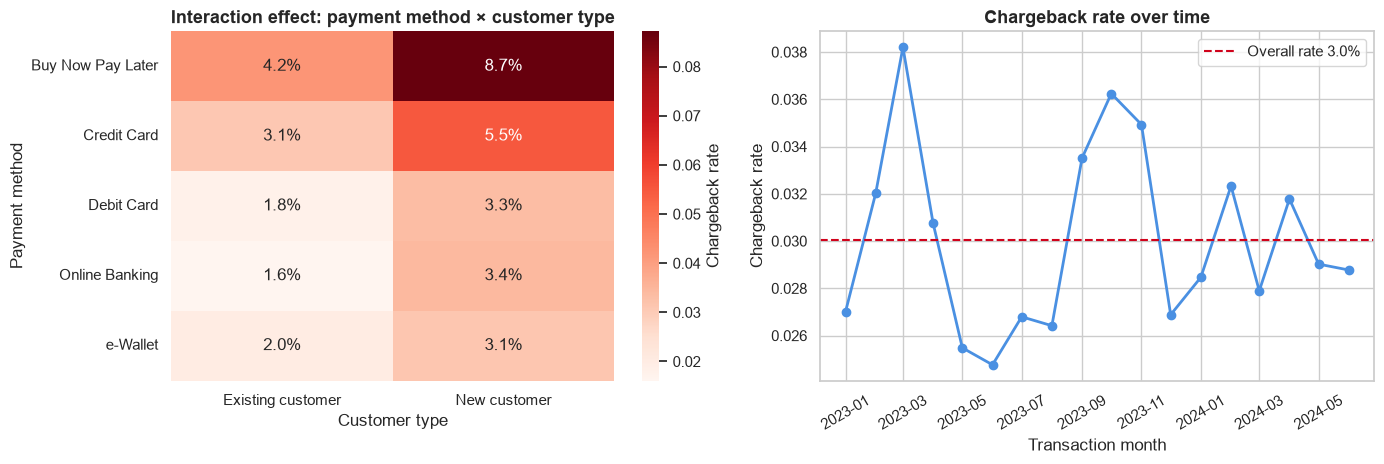

Monthly chargeback rate: min 2.5%, max 3.8%, mean 3.0%
State rate range: Negeri Sembilan 2.2% to Sarawak 4.2%


In [8]:
# Fraud risk is combinatorial, so inspect both interactions and time stability.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

interaction = df.pivot_table(
    index="payment_method", columns="is_new_customer", values="chargeback", observed=True
)
sns.heatmap(
    interaction, annot=True, fmt=".1%", cmap="Reds", ax=axes[0],
    cbar_kws={"label": "Chargeback rate"},
)
axes[0].set_xticklabels(["Existing customer", "New customer"])
axes[0].set_title("Interaction effect: payment method × customer type")
axes[0].set_xlabel("Customer type")
axes[0].set_ylabel("Payment method")

monthly = df.set_index("txn_date")["chargeback"].resample("MS").mean()
axes[1].plot(monthly.index, monthly.values, marker="o", color=BLUE, lw=2)
axes[1].axhline(base_rate, color=RED, ls="--", label=f"Overall rate {base_rate:.1%}")
axes[1].set_xlabel("Transaction month")
axes[1].set_ylabel("Chargeback rate")
axes[1].set_title("Chargeback rate over time")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()

fig.tight_layout()
plt.show()

state_rates = df.groupby("state")["chargeback"].mean().sort_values(ascending=False)
print(
    f"Monthly chargeback rate: min {monthly.min():.1%}, max {monthly.max():.1%}, "
    f"mean {monthly.mean():.1%}"
)
print(
    f"State rate range: {state_rates.index[-1]} {state_rates.iloc[-1]:.1%} "
    f"to {state_rates.index[0]} {state_rates.iloc[0]:.1%}"
)


#### EDA interpretation — what the data tells us

1. **The imbalance is real.** About 97% of transactions are legitimate. Accuracy can therefore look excellent while the model catches no chargebacks, so it is never used for model selection.
2. **Missingness is limited but meaningful.** `account_age_days` and `state` contain gaps. The pipeline retains a missingness flag, imputes numeric values using **training-period** medians, and maps missing categories to `"Unknown"`.
3. **Signals are weak and interaction-heavy.** No standalone field cleanly separates the classes. The payment-method × customer-type heatmap motivates both explicit interaction features and an MLP capable of learning non-linear combinations.
4. **The base rate is reasonably stable, but deployment is still future-facing.** The monthly plot does not show a dramatic shift, yet a random split can let later patterns influence earlier evaluation. The model therefore uses a chronological out-of-time holdout.
5. **The realistic product is a ranking.** The goal is to place a disproportionate number of chargebacks at the top of a finite review queue. We measure that with PR-AUC, recall, precision, lift, and ringgit—not accuracy alone.


### 3. Data refinement: preparing the Shield (A2)

The feature design follows one rule: **every value must have been available when the transaction occurred.** We drop raw IDs, build cyclical timestamp features, add a payment × customer-type interaction, and compute customer history strictly from earlier transactions. Then we split by time before fitting any imputers, category vocabularies, scalers, or resamplers.

* **Chronological 60/20/20 split:** train on the earliest period, tune on the next period, and evaluate on the latest period.
* **Causal history:** prior transaction count, time since prior purchase, prior average / maximum order value, and current-vs-prior order ratio.
* **Leakage-safe fitting:** medians, one-hot columns, scaling statistics, and SMOTENC are all learned from training rows only.
* **Portable scoring:** unseen validation/test categories become all-zero one-hot blocks rather than causing an error or expanding the learned vocabulary.


In [9]:
# ---- Causal feature engineering + ID removal -------------------------------
# Stable ordering makes the history deterministic if two events share a timestamp.
data = df.sort_values(["txn_date", "transaction_id"], kind="stable").copy()

# Cyclical time features avoid treating 23:00 and 00:00 as far apart.
hour = data["txn_date"].dt.hour + data["txn_date"].dt.minute / 60
day_of_week = data["txn_date"].dt.dayofweek
data["txn_hour_sin"] = np.sin(2 * np.pi * hour / 24)
data["txn_hour_cos"] = np.cos(2 * np.pi * hour / 24)
data["txn_dayofweek_sin"] = np.sin(2 * np.pi * day_of_week / 7)
data["txn_dayofweek_cos"] = np.cos(2 * np.pi * day_of_week / 7)
data["is_weekend"] = (day_of_week >= 5).astype(int)

data["account_age_missing"] = data["account_age_days"].isna().astype(int)
data["order_value_per_item"] = data["order_value_myr"] / data["num_items"]
data["log_order_value"] = np.log1p(data["order_value_myr"])

# Explicit interaction: useful with sparse minority labels and still available at score time.
customer_segment = np.where(data["is_new_customer"].eq(1), "new", "existing")
data["payment_customer_segment"] = (
    data["payment_method"].fillna("Unknown").astype(str) + "__" + customer_segment
)

# Historical features are target-free and use only earlier transactions per customer.
customer_groups = data.groupby("customer_id", sort=False)
data["customer_prior_txn_count"] = customer_groups.cumcount().astype(float)
data["customer_days_since_prev_txn"] = (
    customer_groups["txn_date"].diff().dt.total_seconds().div(86_400)
)
prior_order_sum = customer_groups["order_value_myr"].cumsum() - data["order_value_myr"]
data["customer_prior_avg_order_value"] = prior_order_sum.div(
    data["customer_prior_txn_count"].replace(0, np.nan)
)
data["customer_prior_max_order_value"] = customer_groups["order_value_myr"].transform(
    lambda values: values.cummax().shift()
)
data["order_value_vs_prior_avg"] = data["order_value_myr"].div(
    data["customer_prior_avg_order_value"]
).replace([np.inf, -np.inf], np.nan)
data["customer_history_missing"] = (data["customer_prior_txn_count"] == 0).astype(int)

# Keep event time separately for the chronological split, then remove identifiers.
event_time = data["txn_date"].copy()
ID_COLUMNS = ["transaction_id", "customer_id", "txn_date"]
data = data.drop(columns=ID_COLUMNS)

TARGET = "chargeback"
NUMERIC_FEATURES = [
    "order_value_myr", "num_items", "is_new_customer", "account_age_days",
    "account_age_missing", "order_value_per_item", "log_order_value",
    "txn_hour_sin", "txn_hour_cos", "txn_dayofweek_sin", "txn_dayofweek_cos",
    "is_weekend", "customer_prior_txn_count", "customer_days_since_prev_txn",
    "customer_prior_avg_order_value", "customer_prior_max_order_value",
    "order_value_vs_prior_avg", "customer_history_missing",
]
CATEGORICAL_FEATURES = [
    "state", "product_category", "payment_method", "device_type",
    "payment_customer_segment",
]

X = data.drop(columns=[TARGET])
y = data[TARGET].astype(int).to_numpy()

if set(NUMERIC_FEATURES + CATEGORICAL_FEATURES) != set(X.columns):
    raise ValueError("Feature configuration does not match the engineered dataframe")
print(f"Feature matrix before encoding: {X.shape}")
print(f"Numeric features     : {len(NUMERIC_FEATURES)}")
print(f"Categorical features : {CATEGORICAL_FEATURES}")


Feature matrix before encoding: (42000, 23)
Numeric features     : 18
Categorical features : ['state', 'product_category', 'payment_method', 'device_type', 'payment_customer_segment']


In [10]:
# ---- Chronological 60/20/20 split BEFORE fitting any preprocessors ---------
n_rows = len(X)
train_end = int(n_rows * TRAIN_FRACTION)
validation_end = int(n_rows * (TRAIN_FRACTION + VALIDATION_FRACTION))
if not 0 < train_end < validation_end < n_rows:
    raise ValueError("Invalid chronological split configuration")

X_train, X_val, X_test = (
    X.iloc[:train_end].copy(),
    X.iloc[train_end:validation_end].copy(),
    X.iloc[validation_end:].copy(),
)
y_train, y_val, y_test = (
    y[:train_end].copy(),
    y[train_end:validation_end].copy(),
    y[validation_end:].copy(),
)
time_train, time_val, time_test = (
    event_time.iloc[:train_end],
    event_time.iloc[train_end:validation_end],
    event_time.iloc[validation_end:],
)

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "chargebacks": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "positive rate": [y_train.mean(), y_val.mean(), y_test.mean()],
    "start": [time_train.min(), time_val.min(), time_test.min()],
    "end": [time_train.max(), time_val.max(), time_test.max()],
}, index=["train", "validation", "test"])
display(split_summary.round({"positive rate": 4}))

assert time_train.max() < time_val.min() < time_test.min(), "Split must be strictly chronological"
assert min(y_train.sum(), y_val.sum(), y_test.sum()) > 0, "Every split needs chargebacks"


,rows,chargebacks,positive rate,start,end
train,25200,771,0.0306,2023-01-01 00:10:17,2023-11-25 19:54:44
validation,8400,244,0.0290,2023-11-25 19:56:15,2024-03-12 19:55:26
test,8400,247,0.0294,2024-03-12 20:02:48,2024-06-30 23:16:15


In [11]:
# ---- Fit-on-training-period-only preprocessing -----------------------------
# Numeric medians and category fill values are learned from / defined on train only.
TRAIN_MEDIANS = X_train[NUMERIC_FEATURES].median(numeric_only=True)

def impute(part: pd.DataFrame) -> pd.DataFrame:
    part = part.copy()
    part[NUMERIC_FEATURES] = part[NUMERIC_FEATURES].fillna(TRAIN_MEDIANS)
    for column in CATEGORICAL_FEATURES:
        part[column] = part[column].fillna("Unknown").astype(str)
    return part


X_train = impute(X_train)
X_val = impute(X_val)
X_test = impute(X_test)

# Training vocabulary only: unseen categories in later periods map to all-zero dummies.
X_train_enc = pd.get_dummies(X_train, columns=CATEGORICAL_FEATURES, dtype=np.float32)
FEATURE_NAMES = list(X_train_enc.columns)
X_val_enc = (
    pd.get_dummies(X_val, columns=CATEGORICAL_FEATURES, dtype=np.float32)
    .reindex(columns=FEATURE_NAMES, fill_value=0.0)
)
X_test_enc = (
    pd.get_dummies(X_test, columns=CATEGORICAL_FEATURES, dtype=np.float32)
    .reindex(columns=FEATURE_NAMES, fill_value=0.0)
)

# Fit scaling statistics on the historical training period only.
scaler = StandardScaler().fit(X_train_enc)
X_train_s = scaler.transform(X_train_enc).astype(np.float32)
X_val_s = scaler.transform(X_val_enc).astype(np.float32)
X_test_s = scaler.transform(X_test_enc).astype(np.float32)

print(f"Encoded feature space: {X_train_s.shape[1]} columns")
print(f"Example features     : {FEATURE_NAMES[:8]} ...")


Encoded feature space: 61 columns
Example features     : ['order_value_myr', 'num_items', 'is_new_customer', 'account_age_days', 'txn_hour_sin', 'txn_hour_cos', 'txn_dayofweek_sin', 'txn_dayofweek_cos'] ...


#### Integrity verification

The checks below are deliberately executable evidence, not just comments: they prove the temporal ordering, shared encoded schema, finite inputs, and training-only fit statistics. If any check fails, stop and resolve it before training.


In [12]:
checks = {
    "Chronological boundaries are ordered": time_train.max() < time_val.min() < time_test.min(),
    "Train means are ~0 (scaler fitted on train)": np.allclose(X_train_s.mean(axis=0), 0, atol=1e-6),
    "Train stds are ~1": np.allclose(X_train_s.std(axis=0), 1, atol=1e-3),
    "Validation matrix is finite": np.isfinite(X_val_s).all(),
    "Test matrix is finite": np.isfinite(X_test_s).all(),
    "Same encoded schema across periods": (
        list(X_val_enc.columns) == FEATURE_NAMES and list(X_test_enc.columns) == FEATURE_NAMES
    ),
    "No nulls after preprocessing": not (
        np.isnan(X_train_s).any() or np.isnan(X_val_s).any() or np.isnan(X_test_s).any()
    ),
    "History flag agrees with prior-count feature": np.array_equal(
        (X_train["customer_prior_txn_count"].to_numpy() == 0).astype(int),
        X_train["customer_history_missing"].to_numpy().astype(int),
    ),
}
for description, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {description}")

assert all(checks.values()), "Temporal / preprocessing integrity audit failed!"


[PASS] Chronological boundaries are ordered
[PASS] Train means are ~0 (scaler fitted on train)
[PASS] Train stds are ~1
[PASS] Validation matrix is finite
[PASS] Test matrix is finite
[PASS] Same encoded schema across periods
[PASS] No nulls after preprocessing
[PASS] History flag agrees with prior-count feature


In [13]:
# ---- Imbalance tooling: class weights + moderate SMOTENC -------------------
# Both tools touch training rows only. SMOTENC is intentionally capped at a
# 1:2 minority/majority ratio rather than fabricating a fully balanced world.
weights = class_weight.compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHTS = {0: float(weights[0]), 1: float(weights[1])}
print(f"Class weights: legitimate = {CLASS_WEIGHTS[0]:.3f}, chargeback = {CLASS_WEIGHTS[1]:.3f}")

# Ordinal-code categoricals only inside SMOTENC, then restore categories and
# one-hot encode using the original training vocabulary.
smote_input = X_train.copy()
category_levels = {}
for column in CATEGORICAL_FEATURES:
    levels = sorted(smote_input[column].astype(str).unique())
    category_levels[column] = levels
    code_map = {value: index for index, value in enumerate(levels)}
    smote_input[column] = smote_input[column].astype(str).map(code_map).astype(int)

categorical_indices = [smote_input.columns.get_loc(column) for column in CATEGORICAL_FEATURES]
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=SMOTE_TARGET_RATIO,
    random_state=SEED,
)
X_train_res_raw, y_train_res = smotenc.fit_resample(smote_input, y_train)
X_train_res_raw = pd.DataFrame(X_train_res_raw, columns=X_train.columns)
for column, levels in category_levels.items():
    codes = X_train_res_raw[column].round().clip(0, len(levels) - 1).astype(int)
    X_train_res_raw[column] = codes.map(dict(enumerate(levels)))

X_train_res_enc = pd.get_dummies(
    X_train_res_raw, columns=CATEGORICAL_FEATURES, dtype=np.float32
).reindex(columns=FEATURE_NAMES, fill_value=0.0)
X_train_res = scaler.transform(X_train_res_enc).astype(np.float32)

print(
    f"Training set before SMOTENC: {X_train_s.shape[0]:,} rows "
    f"({int(y_train.sum()):,} chargebacks)"
)
print(
    f"Training set after  SMOTENC: {X_train_res.shape[0]:,} rows "
    f"({int(y_train_res.sum()):,} chargebacks)"
)


Class weights: legitimate = 0.516, chargeback = 16.342


Training set before SMOTENC: 25,200 rows (771 chargebacks)
Training set after  SMOTENC: 36,643 rows (12,214 chargebacks)


### 4. Model architecture (A2)

The Financial Shield stays deliberately compact: the dataset has tens of thousands of rows and modest signal, so a very deep network would mostly memorise noise. The MLP can still learn the non-linear combinations suggested by the EDA—such as a new customer, a payment type, a recent purchase pattern, and a high current order value occurring together.

```
Input (encoded transaction + causal history)
  → Dense(128) → BatchNorm → LeakyReLU(0.1) → Dropout(0.30)
  → Dense(64)  → BatchNorm → LeakyReLU(0.1) → Dropout(0.20)
  → Dense(1, sigmoid)  # risk score
```

Training tracks **PR-AUC**, the right discriminative measure for a rare positive class. The next section compares four imbalance strategies with the same architecture, maximum epochs, callbacks, and seed; only the loss or sampling treatment changes.


In [14]:
def build_financial_shield(input_dim: int, learning_rate: float = 1e-3):
    """128->64 MLP with BatchNorm + LeakyReLU + Dropout, built for imbalanced data."""
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),

        # Foundational layer
        layers.Dense(128),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.1),
        layers.Dropout(0.3),

        # Refining layer
        layers.Dense(64),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.1),
        layers.Dropout(0.2),

        # Risk-probability output
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc", curve="PR")],
    )
    return model

tf.keras.utils.set_random_seed(SEED)
architecture_preview = build_financial_shield(X_train_s.shape[1])
architecture_preview.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         7,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 16,641 (65.00 KB)

 Non-trainable params: 384 (1.50 KB)

### 5. Training the Shield — four comparable imbalance strategies

Each candidate uses the same architecture, seed, maximum training budget, batch size, and PR-AUC early-stopping logic. The **only intended difference** is how it addresses imbalance:

| Strategy | Imbalance handling |
|---|---|
| Baseline | None; exposes majority-class collapse |
| Class weights | Up-weights chargebacks in binary cross-entropy |
| SMOTENC | Moderately oversamples the training-period minority class (1:2) |
| Focal loss | Down-weights easy examples and emphasises rare / hard chargebacks |

Candidate selection uses **validation PR-AUC only**. The final test-period score is intentionally unavailable in this section.


In [15]:
%%time
# ---------------------------------------------------------------------------
# Candidate selection is validation-only. Do NOT score X_test here: seeing
# candidate test metrics can influence selection even if code says otherwise.
# ---------------------------------------------------------------------------
MAX_EPOCHS = 60
STRATEGIES = {
    "1. Baseline (no balancing)": dict(use_smote=False, use_class_weight=False, use_focal=False),
    "2. Class weights": dict(use_smote=False, use_class_weight=True, use_focal=False),
    "3. SMOTENC (1:2)": dict(use_smote=True, use_class_weight=False, use_focal=False),
    "4. Focal loss": dict(use_smote=False, use_class_weight=False, use_focal=True),
}


def training_callbacks():
    return [
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_auc", mode="max", factor=0.5, patience=3, min_lr=1e-5, verbose=0
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_auc", mode="max", patience=7, restore_best_weights=True, verbose=0
        ),
    ]


def train_strategy(config: dict, seed: int = SEED) -> dict:
    """Train one candidate and return validation-only evidence."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = build_financial_shield(X_train_s.shape[1])

    if config["use_focal"]:
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
            loss=tf.keras.losses.BinaryFocalCrossentropy(
                gamma=2.0, alpha=0.75, apply_class_balancing=True
            ),
            metrics=[tf.keras.metrics.AUC(name="auc", curve="PR")],
        )

    x_fit, y_fit = (X_train_res, y_train_res) if config["use_smote"] else (X_train_s, y_train)
    history = model.fit(
        x=x_fit,
        y=y_fit,
        validation_data=(X_val_s, y_val),
        epochs=MAX_EPOCHS,
        batch_size=128,
        class_weight=CLASS_WEIGHTS if config["use_class_weight"] else None,
        callbacks=training_callbacks(),
        verbose=0,
    )
    p_val = model.predict(X_val_s, verbose=0).reshape(-1)
    return {"model": model, "history": pd.DataFrame(history.history), "p_val": p_val}


results = {}
for name, config in STRATEGIES.items():
    print(f"Training {name} ...", end=" ", flush=True)
    results[name] = train_strategy(config)
    validation_scores = results[name]["p_val"]
    print(
        f"validation PR-AUC {average_precision_score(y_val, validation_scores):.4f} | "
        f"validation ROC-AUC {roc_auc_score(y_val, validation_scores):.4f}"
    )


Training 1. Baseline (no balancing) ... 

E0000 00:00:1794636024.652671   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


validation PR-AUC 0.0424 | validation ROC-AUC 0.5577
Training 2. Class weights ... 

E0000 00:00:1794636030.644280   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


validation PR-AUC 0.0422 | validation ROC-AUC 0.5815
Training 3. SMOTENC (1:2) ... 

validation PR-AUC 0.0310 | validation ROC-AUC 0.5317
Training 4. Focal loss ... 

E0000 00:00:1794636038.100668   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


validation PR-AUC 0.0405 | validation ROC-AUC 0.5684
CPU times: user 21.7 s, sys: 1.24 s, total: 22.9 s
Wall time: 21.4 s


E0000 00:00:1794636045.631002   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,Validation PR-AUC,Validation ROC-AUC,Validation recall @0.5,Epochs trained
1. Baseline (no balancing),0.0424,0.5577,0.0000,9.0
2. Class weights,0.0422,0.5815,0.4549,10.0
3. SMOTENC (1:2),0.0310,0.5317,0.0410,8.0
4. Focal loss,0.0405,0.5684,0.0000,21.0


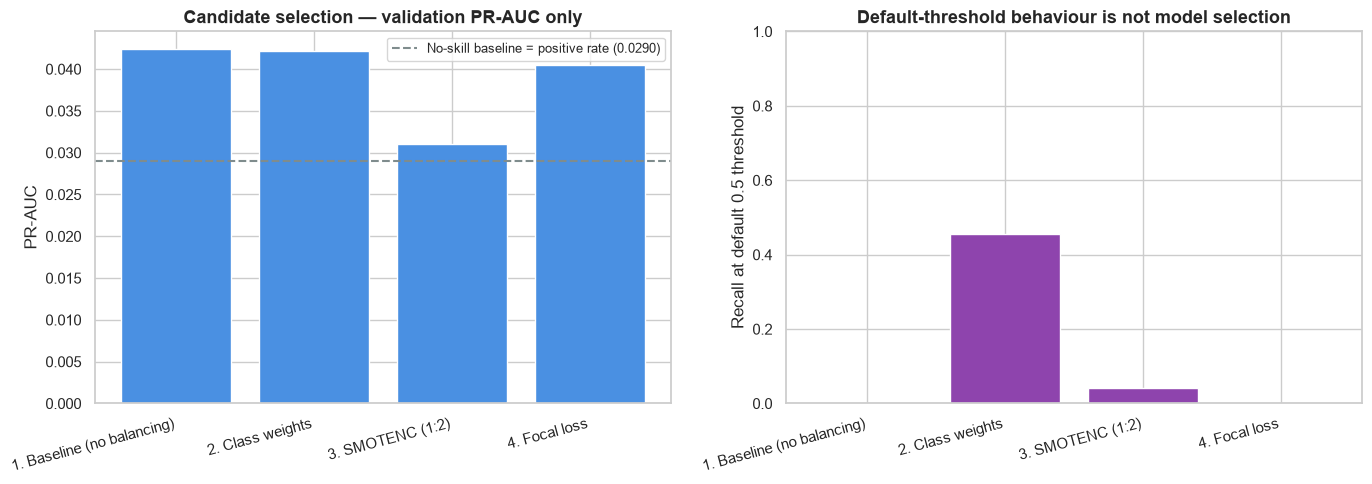

Selected final model (highest validation PR-AUC): 1. Baseline (no balancing)


In [16]:
# ---- Validation-only candidate comparison -----------------------------------
summary = pd.DataFrame({
    name: {
        "Validation PR-AUC": average_precision_score(y_val, result["p_val"]),
        "Validation ROC-AUC": roc_auc_score(y_val, result["p_val"]),
        "Validation recall @0.5": recall_score(
            y_val, (result["p_val"] >= 0.5).astype(int), zero_division=0
        ),
        "Epochs trained": len(result["history"]),
    }
    for name, result in results.items()
}).T
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
positions = np.arange(len(summary))
axes[0].bar(positions, summary["Validation PR-AUC"], color=BLUE)
axes[0].axhline(
    y_val.mean(), color=GREY, linestyle="--",
    label=f"No-skill baseline = positive rate ({y_val.mean():.4f})",
)
axes[0].set_xticks(positions)
axes[0].set_xticklabels(summary.index, rotation=15, ha="right")
axes[0].set_ylabel("PR-AUC")
axes[0].set_title("Candidate selection — validation PR-AUC only")
axes[0].legend(fontsize=9)

axes[1].bar(positions, summary["Validation recall @0.5"], color=PURPLE)
axes[1].set_xticks(positions)
axes[1].set_xticklabels(summary.index, rotation=15, ha="right")
axes[1].set_ylabel("Recall at default 0.5 threshold")
axes[1].set_ylim(0, 1)
axes[1].set_title("Default-threshold behaviour is not model selection")

fig.tight_layout()
plt.show()

FINAL_STRATEGY = summary["Validation PR-AUC"].idxmax()
print(f"Selected final model (highest validation PR-AUC): {FINAL_STRATEGY}")


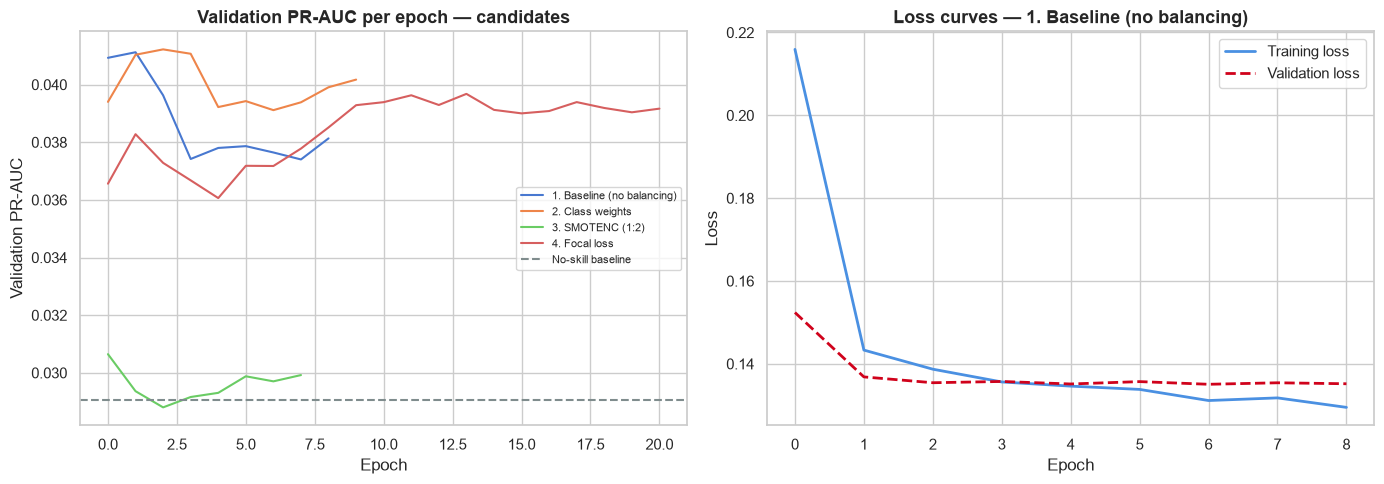

In [17]:
# ---- Convergence diagnostics ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, result in results.items():
    axes[0].plot(result["history"]["val_auc"], label=name)
axes[0].axhline(y_val.mean(), color=GREY, linestyle="--", label="No-skill baseline")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation PR-AUC")
axes[0].set_title("Validation PR-AUC per epoch — candidates")
axes[0].legend(fontsize=8)

winner_history = results[FINAL_STRATEGY]["history"]
axes[1].plot(winner_history["loss"], color=BLUE, lw=2, label="Training loss")
axes[1].plot(winner_history["val_loss"], color=RED, lw=2, ls="--", label="Validation loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_title(f"Loss curves — {FINAL_STRATEGY}")
axes[1].legend()

fig.tight_layout()
plt.show()


#### Interpretation — candidate comparison

* A candidate is selected strictly by **validation PR-AUC**, which measures minority-class ranking quality without committing to one operational threshold.
* The default 0.5-threshold recall chart is diagnostic only. A rebalanced loss can shift score scale substantially, so production operating points must be chosen separately on validation data or by an explicit review-capacity policy.
* Do not infer generalisation from this section: no candidate test metric has been produced yet. The latest 20% of transactions remains the final out-of-time check.
* If validation PR-AUC remains only slightly above the positive rate, the correct conclusion is that the available features support a modest triage signal—not an automated fraud-blocking system.


### 6. Measuring the Shield — final out-of-time evaluation (A3/A4)

The validation-selected winner becomes the Financial Shield. Only now do we score the latest 20% of transactions. The test period provides:

* PR and ROC curves, with a bootstrap 95% confidence interval for PR-AUC;
* three review policies: validation-max-F1, strictest threshold achieving target validation recall, and a fixed-capacity top-10% queue;
* raw and row-normalised confusion matrices, plus a policy comparison table;
* a direct comparison with the misleading “always legitimate” baseline.

No strategy, feature, epoch, or threshold is selected using test labels.


Final model        : 1. Baseline (no balancing)
Validation PR-AUC  : 0.0424
Test PR-AUC        : 0.0455 (95% bootstrap CI 0.0366–0.0599)
Test ROC-AUC       : 0.5890
Test positive rate : 0.0294 (no-skill PR-AUC reference)


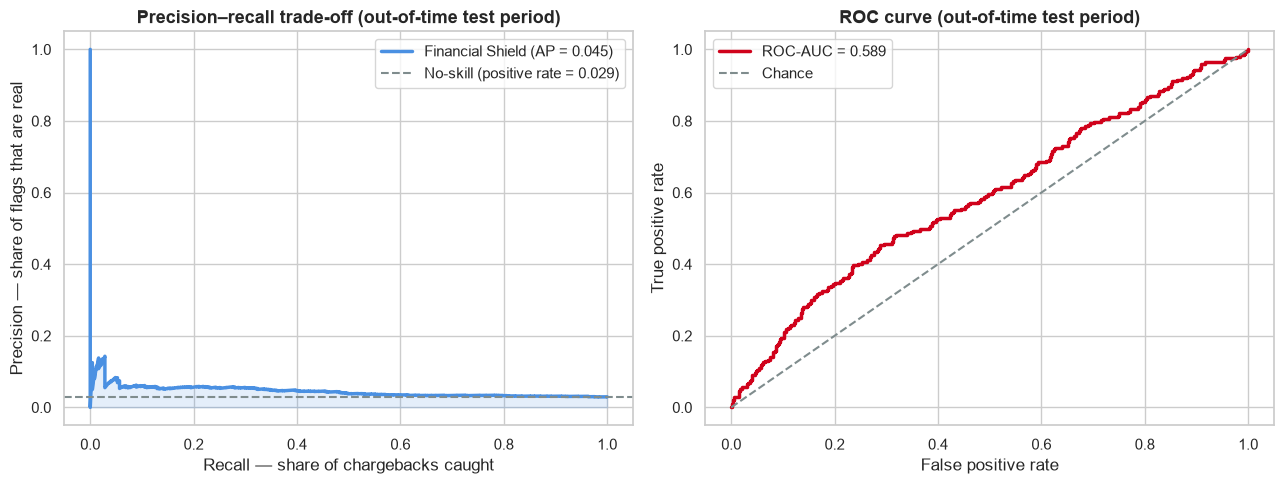

In [18]:
# ---- One final score of the untouched out-of-time test period ---------------
final_model = results[FINAL_STRATEGY]["model"]
p_val = results[FINAL_STRATEGY]["p_val"]
p_test = final_model.predict(X_test_s, verbose=0).reshape(-1)


def bootstrap_average_precision_ci(y_true, scores, n_bootstraps=N_BOOTSTRAPS, seed=SEED):
    """Non-parametric 95% CI for held-out PR-AUC."""
    rng = np.random.default_rng(seed)
    samples = []
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    while len(samples) < n_bootstraps:
        index = rng.integers(0, len(y_true), size=len(y_true))
        sample_y = y_true[index]
        if sample_y.min() == sample_y.max():
            continue
        samples.append(average_precision_score(sample_y, scores[index]))
    return tuple(np.quantile(samples, [0.025, 0.975]))


test_pr_auc = average_precision_score(y_test, p_test)
pr_auc_ci_low, pr_auc_ci_high = bootstrap_average_precision_ci(y_test, p_test)
test_roc_auc = roc_auc_score(y_test, p_test)

print(f"Final model        : {FINAL_STRATEGY}")
print(f"Validation PR-AUC  : {average_precision_score(y_val, p_val):.4f}")
print(f"Test PR-AUC        : {test_pr_auc:.4f} (95% bootstrap CI {pr_auc_ci_low:.4f}–{pr_auc_ci_high:.4f})")
print(f"Test ROC-AUC       : {test_roc_auc:.4f}")
print(f"Test positive rate : {y_test.mean():.4f} (no-skill PR-AUC reference)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

precisions, recalls, _ = precision_recall_curve(y_test, p_test)
axes[0].plot(
    recalls, precisions, color=BLUE, lw=2.5,
    label=f"Financial Shield (AP = {test_pr_auc:.3f})",
)
axes[0].fill_between(recalls, precisions, alpha=0.15, color=BLUE)
axes[0].axhline(
    y_test.mean(), color=GREY, ls="--",
    label=f"No-skill (positive rate = {y_test.mean():.3f})",
)
axes[0].set_xlabel("Recall — share of chargebacks caught")
axes[0].set_ylabel("Precision — share of flags that are real")
axes[0].set_title("Precision–recall trade-off (out-of-time test period)")
axes[0].legend()

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, color=RED, lw=2.5, label=f"ROC-AUC = {test_roc_auc:.3f}")
axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", label="Chance")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve (out-of-time test period)")
axes[1].legend()

fig.tight_layout()
plt.show()


Balanced mode    : threshold 0.0649 (validation precision 0.047, recall 0.291)
High-recall mode : threshold 0.0172 (validation precision 0.029, recall 0.902)
Capacity mode    : top 10% = 840 test transactions (score cutoff 0.0778; no labels used)

--- TEST — Balanced mode (validation max-F1) ---
              precision    recall  f1-score   support

  Legitimate       0.98      0.83      0.90      8153
  Chargeback       0.05      0.31      0.09       247

    accuracy                           0.82      8400
   macro avg       0.51      0.57      0.50      8400
weighted avg       0.95      0.82      0.88      8400


--- TEST — Capacity mode (top 10% risk queue) ---
              precision    recall  f1-score   support

  Legitimate       0.97      0.90      0.94      8153
  Chargeback       0.06      0.19      0.09       247

    accuracy                           0.88      8400
   macro avg       0.52      0.55      0.51      8400
weighted avg       0.95      0.88      0.91      8400

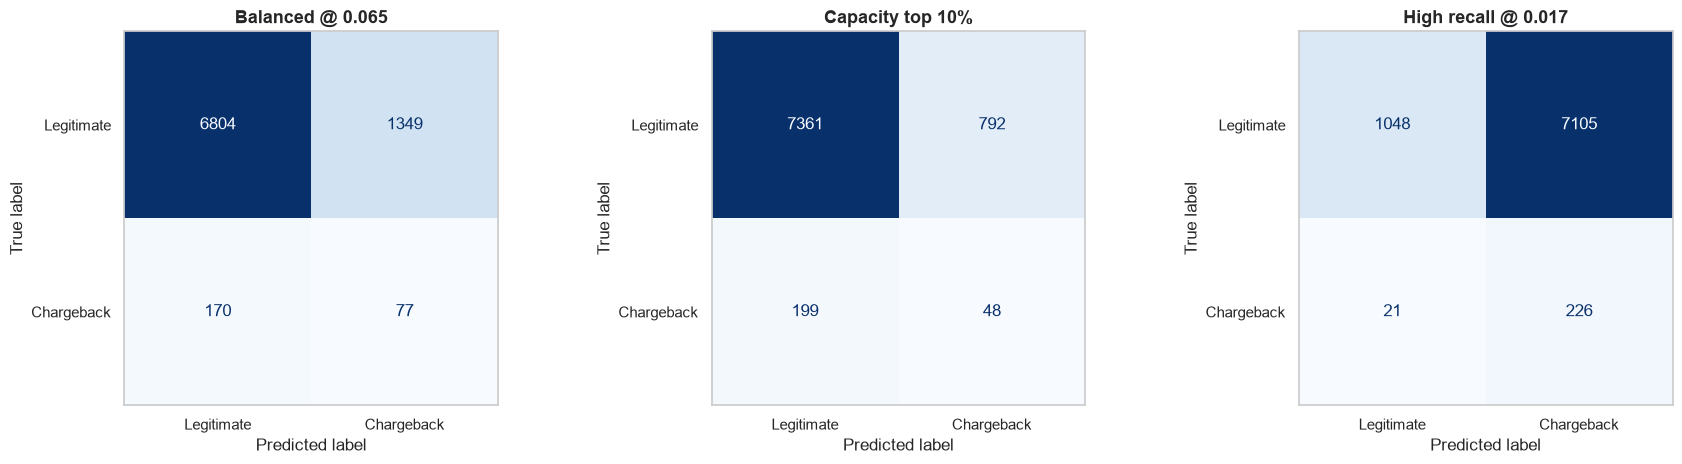

In [19]:
# ---------------------------------------------------------------------------
# Thresholds are tuned on validation only. The capacity policy uses no labels:
# it always routes the top REVIEW_BUDGET_FRACTION of current transactions.
# ---------------------------------------------------------------------------
precision_val, recall_val, thresholds_val = precision_recall_curve(y_val, p_val)
f1_val = 2 * precision_val * recall_val / (precision_val + recall_val + 1e-12)

# Mode 1: validation threshold that maximises F1.
best_f1_index = int(np.nanargmax(f1_val[:-1]))
THRESHOLD_BALANCED = float(thresholds_val[best_f1_index])

# Mode 2: because thresholds are ascending and recall decreases as the
# threshold tightens, the LAST eligible index is the strictest valid cutoff.
eligible = np.flatnonzero(recall_val[:-1] >= TARGET_RECALL)
if len(eligible):
    high_recall_index = int(eligible[-1])
else:
    high_recall_index = int(np.nanargmax(recall_val[:-1]))
    print(
        f"Warning: validation recall target {TARGET_RECALL:.0%} was not attainable; "
        f"using maximum observed recall {recall_val[high_recall_index]:.3f}."
    )
THRESHOLD_HIGH_RECALL = float(thresholds_val[high_recall_index])


def top_k_predictions(scores, fraction):
    """Return a deterministic top-k queue, preserving an exact capacity."""
    n_selected = max(1, int(np.ceil(len(scores) * fraction)))
    ranked_index = np.argsort(-np.asarray(scores), kind="mergesort")
    predictions = np.zeros(len(scores), dtype=int)
    predictions[ranked_index[:n_selected]] = 1
    cutoff = float(np.asarray(scores)[ranked_index[n_selected - 1]])
    return predictions, n_selected, cutoff


def report_predictions(predictions, title):
    print(f"\n--- {title} ---")
    print(
        classification_report(
            y_test, predictions, target_names=["Legitimate", "Chargeback"], zero_division=0
        )
    )
    return confusion_matrix(y_test, predictions)


pred_balanced = (p_test >= THRESHOLD_BALANCED).astype(int)
pred_high_recall = (p_test >= THRESHOLD_HIGH_RECALL).astype(int)
pred_capacity, capacity_count, capacity_cutoff = top_k_predictions(
    p_test, REVIEW_BUDGET_FRACTION
)

print(
    f"Balanced mode    : threshold {THRESHOLD_BALANCED:.4f} "
    f"(validation precision {precision_val[best_f1_index]:.3f}, "
    f"recall {recall_val[best_f1_index]:.3f})"
)
print(
    f"High-recall mode : threshold {THRESHOLD_HIGH_RECALL:.4f} "
    f"(validation precision {precision_val[high_recall_index]:.3f}, "
    f"recall {recall_val[high_recall_index]:.3f})"
)
print(
    f"Capacity mode    : top {REVIEW_BUDGET_FRACTION:.0%} = {capacity_count:,} test transactions "
    f"(score cutoff {capacity_cutoff:.4f}; no labels used)"
)

cm_balanced = report_predictions(pred_balanced, "TEST — Balanced mode (validation max-F1)")
cm_capacity = report_predictions(
    pred_capacity, f"TEST — Capacity mode (top {REVIEW_BUDGET_FRACTION:.0%} risk queue)"
)
cm_high_recall = report_predictions(
    pred_high_recall, f"TEST — High-recall mode (validation target {TARGET_RECALL:.0%})"
)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, matrix, title in [
    (axes[0], cm_balanced, f"Balanced @ {THRESHOLD_BALANCED:.3f}"),
    (axes[1], cm_capacity, f"Capacity top {REVIEW_BUDGET_FRACTION:.0%}"),
    (axes[2], cm_high_recall, f"High recall @ {THRESHOLD_HIGH_RECALL:.3f}"),
]:
    ConfusionMatrixDisplay(matrix, display_labels=["Legitimate", "Chargeback"]).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(title)
    ax.grid(False)
fig.tight_layout()
plt.show()


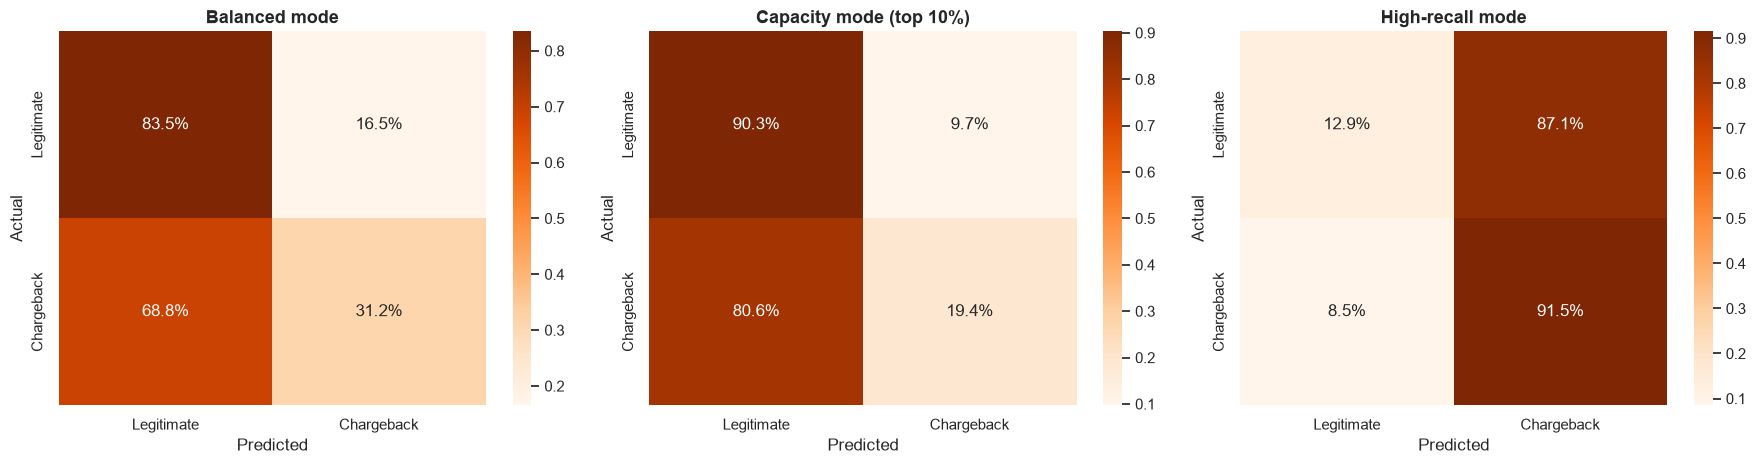

In [20]:
# Row-normalised views show the share of each true class captured by each policy.
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, matrix, title in [
    (axes[0], cm_balanced, "Balanced mode"),
    (axes[1], cm_capacity, f"Capacity mode (top {REVIEW_BUDGET_FRACTION:.0%})"),
    (axes[2], cm_high_recall, "High-recall mode"),
]:
    matrix_normalised = matrix.astype(float) / matrix.sum(axis=1, keepdims=True)
    sns.heatmap(
        matrix_normalised, annot=True, fmt=".1%", cmap="Oranges",
        xticklabels=["Legitimate", "Chargeback"],
        yticklabels=["Legitimate", "Chargeback"], ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.tight_layout()
plt.show()


In [21]:
# ---- Policy assessment vs. the misleading always-legitimate baseline --------
def policy_metrics(predictions, confusion):
    true_positives = int(confusion[1, 1])
    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "Recall (chargeback)": recall_score(y_test, predictions, zero_division=0),
        "Precision (chargeback)": precision_score(y_test, predictions, zero_division=0),
        "Flag rate": predictions.mean(),
        "Potential RM loss prevented": true_positives * RM_PER_CHARGEBACK,
    }


pred_naive = np.zeros_like(y_test)
cm_naive = confusion_matrix(y_test, pred_naive)
policy_comparison = pd.DataFrame({
    "Naive (always legitimate)": policy_metrics(pred_naive, cm_naive),
    "Balanced (validation max-F1)": policy_metrics(pred_balanced, cm_balanced),
    f"Capacity (top {REVIEW_BUDGET_FRACTION:.0%})": policy_metrics(pred_capacity, cm_capacity),
    f"High recall (validation {TARGET_RECALL:.0%})": policy_metrics(
        pred_high_recall, cm_high_recall
    ),
}).T
display(policy_comparison.round(4))

print(
    f"Risk-ranking PR-AUC is {test_pr_auc:.4f} versus a no-skill reference of {y_test.mean():.4f}. "
    "Policy rows above are threshold-specific; PR-AUC is not."
)
print(
    "Potential loss prevented assumes a flagged true chargeback is successfully stopped or resolved "
    "by the downstream review process; it excludes review labour and customer-friction costs."
)


,Accuracy,Balanced accuracy,Recall (chargeback),Precision (chargeback),Flag rate,Potential RM loss prevented
Naive (always legitimate),0.9706,0.5000,0.0000,0.0000,0.0000,0.0
Balanced (validation max-F1),0.8192,0.5731,0.3117,0.0540,0.1698,6545.0
Capacity (top 10%),0.8820,0.5486,0.1943,0.0571,0.1000,4080.0
High recall (validation 90%),0.1517,0.5218,0.9150,0.0308,0.8727,19210.0


Risk-ranking PR-AUC is 0.0455 versus a no-skill reference of 0.0294. Policy rows above are threshold-specific; PR-AUC is not.
Potential loss prevented assumes a flagged true chargeback is successfully stopped or resolved by the downstream review process; it excludes review labour and customer-friction costs.


#### Metric justification — why accuracy is the wrong yardstick

A model predicting “legitimate” for every row is about 97% accurate, yet catches no chargebacks. This notebook therefore reports:

* **PR-AUC (primary ranking metric):** compares precision and recall across every threshold; the no-skill reference is the observed positive rate.
* **Bootstrap PR-AUC interval:** communicates how uncertain the final out-of-time ranking estimate is, rather than over-reading a single split.
* **Recall and precision:** show the share of losses reached and how concentrated the review queue is.
* **Capacity and flag rate:** expose whether an operating mode is feasible for people to review.
* **Balanced accuracy:** prevents majority-class performance from hiding minority-class failure.

`RM_PER_CHARGEBACK` translates caught chargebacks into **potential** gross loss avoided. A deployment business case must additionally include review labour, false-positive friction, and the actual effectiveness of intervention.


### 7. Model insight (A4): what drives the risk score—and can we trust it?

Two complementary diagnostics interrogate the validation-selected model:

1. **Permutation importance on the validation period:** randomly shuffle one feature at a time and measure the resulting drop in PR-AUC. One-hot variables are grouped back to their source feature so stakeholders see “payment method,” not just dummy columns.
2. **Calibration on the final test period:** compare raw model scores with observed chargeback rates. Resampling and class-weighted objectives can improve ranking while distorting literal probability estimates.

Importance uses validation data deliberately, so the final test labels are not reused for exploratory feature discovery.


E0000 00:00:1794636050.749395   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1794636055.785167   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1794636060.815382   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1794636065.909755   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1794636070.974540   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1794636076.090941   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


... (6 outputs left out)

E0000 00:00:1794636111.415557   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1794636116.476034   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1794636121.515769   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1794636126.529830   63842 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


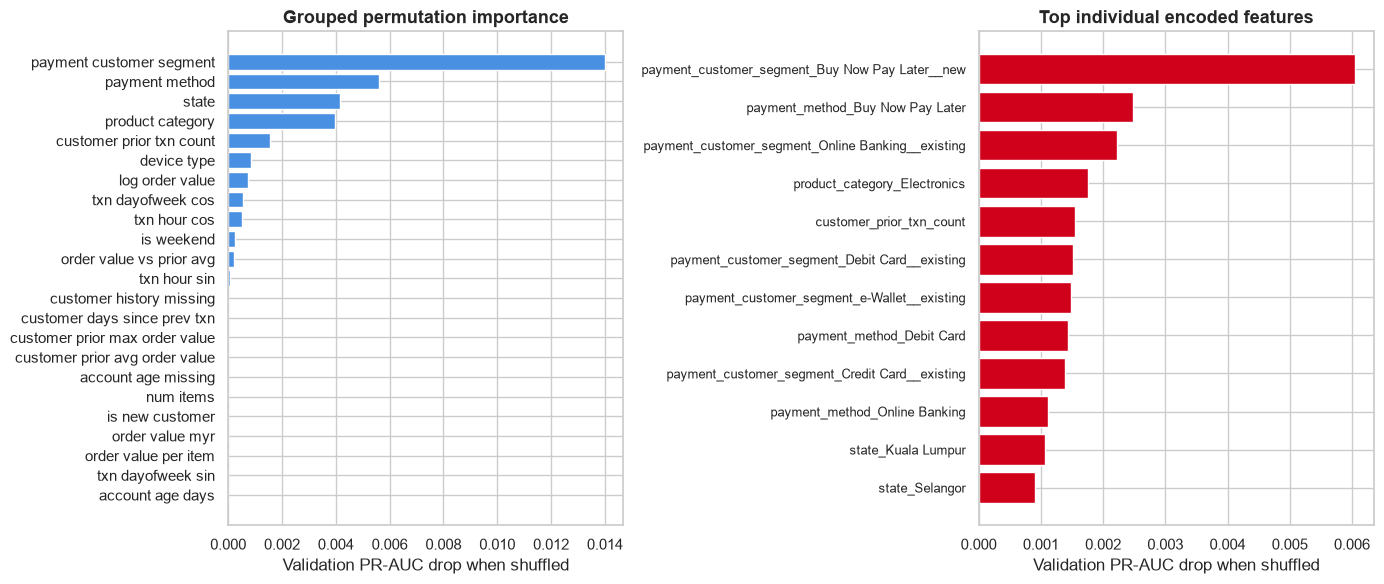

,mean PR-AUC drop,std
payment_customer_segment_Buy Now Pay Later__new,0.00605,0.00148
payment_method_Buy Now Pay Later,0.00248,0.00058
payment_customer_segment_Online Banking__existing,0.00222,0.00098
product_category_Electronics,0.00176,0.00080
customer_prior_txn_count,0.00155,0.00111
payment_customer_segment_Debit Card__existing,0.00152,0.00078
payment_customer_segment_e-Wallet__existing,0.00149,0.00127
payment_method_Debit Card,0.00144,0.00090
payment_customer_segment_Credit Card__existing,0.00138,0.00116
payment_method_Online Banking,0.00111,0.00079


In [22]:
class KerasClassifierWrapper(BaseEstimator, ClassifierMixin):
    """Expose a trained Keras binary classifier to scikit-learn diagnostics."""

    def __init__(self, keras_model):
        self.keras_model = keras_model
        self.classes_ = np.array([0, 1])

    def fit(self, X, y=None):
        return self

    def predict_proba(self, X):
        probabilities = self.keras_model.predict(np.asarray(X), verbose=0).reshape(-1)
        return np.column_stack([1 - probabilities, probabilities])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

    def decision_function(self, X):
        return self.keras_model.predict(np.asarray(X), verbose=0).reshape(-1)


permutation = permutation_importance(
    KerasClassifierWrapper(final_model),
    X_val_s,
    y_val,
    n_repeats=10,
    random_state=SEED,
    scoring="average_precision",
)
importance = pd.DataFrame({
    "mean_ap_drop": permutation.importances_mean,
    "std_ap_drop": permutation.importances_std,
}, index=FEATURE_NAMES)

ONE_HOT_PREFIXES = (
    "state_", "product_category_", "payment_method_", "device_type_",
    "payment_customer_segment_",
)


def group_name(column):
    for prefix in ONE_HOT_PREFIXES:
        if column.startswith(prefix):
            return prefix.rstrip("_").replace("_", " ")
    return column.replace("_", " ")


# Negative drops are sampling noise, not evidence that shuffling helps.
grouped = (
    importance["mean_ap_drop"].clip(lower=0).groupby(group_name).sum().sort_values()
)
top_individual = importance["mean_ap_drop"].sort_values(ascending=False).head(12).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(range(len(grouped)), grouped.values, color=BLUE)
axes[0].set_yticks(range(len(grouped)))
axes[0].set_yticklabels(grouped.index)
axes[0].set_xlabel("Validation PR-AUC drop when shuffled")
axes[0].set_title("Grouped permutation importance")

axes[1].barh(range(len(top_individual)), top_individual.values, color=RED)
axes[1].set_yticks(range(len(top_individual)))
axes[1].set_yticklabels(top_individual.index, fontsize=9)
axes[1].set_xlabel("Validation PR-AUC drop when shuffled")
axes[1].set_title("Top individual encoded features")

fig.tight_layout()
plt.show()

display(
    importance.sort_values("mean_ap_drop", ascending=False)
    .head(10)
    .rename(columns={"mean_ap_drop": "mean PR-AUC drop", "std_ap_drop": "std"})
    .round(5)
)


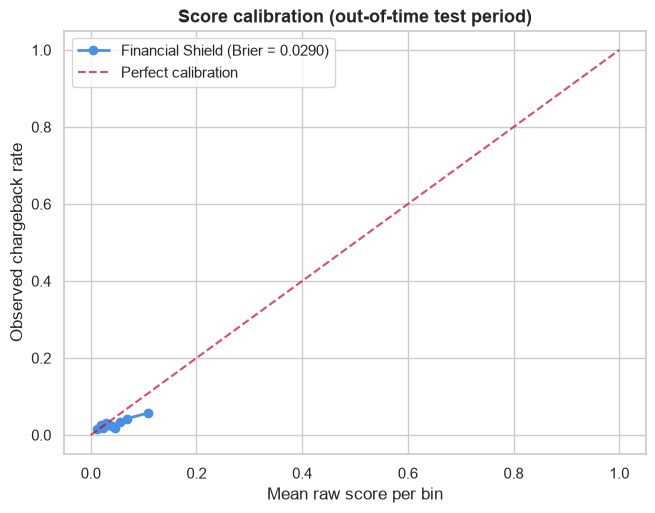

Brier score                    : 0.0290
Always-predict-base-rate Brier : 0.0285


In [23]:
# Raw scores may be useful rankings without being calibrated probabilities.
probability_true, probability_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
brier = brier_score_loss(y_test, p_test)
brier_base = y_test.mean() * (1 - y_test.mean())

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(
    probability_pred, probability_true, marker="o", color=BLUE, lw=2,
    label=f"Financial Shield (Brier = {brier:.4f})",
)
ax.plot([0, 1], [0, 1], ls="--", color=RED, alpha=0.7, label="Perfect calibration")
ax.set_xlabel("Mean raw score per bin")
ax.set_ylabel("Observed chargeback rate")
ax.set_title("Score calibration (out-of-time test period)")
ax.legend()
plt.show()

print(f"Brier score                    : {brier:.4f}")
print(f"Always-predict-base-rate Brier : {brier_base:.4f}")


#### Interpretation — importance and calibration

* Treat the importance chart as **associational**: a feature with a positive validation PR-AUC drop contributes to the current ranking, but the chart does not establish causation or fairness.
* Review whether the leading signals are stable and operationally available at scoring time before relying on them. A feature that is unavailable, delayed, or easily manipulated cannot support a real-time policy.
* The model may be a useful ranking even when its raw scores are poor probabilities. Class weighting, focal loss, and SMOTENC alter the effective training prevalence, so probability calibration should be fitted on a separate recent labelled set before exposing a “fraud probability” to stakeholders.
* A weak or unstable importance profile is evidence to collect better signals—not a reason to automate declines. Device fingerprints, verified address / payment relationships, and prior reviewed outcomes would be higher-value additions.


### 8. Business impact analysis (A5): translating ranking into ringgit

Operations does not choose a threshold in a vacuum; it chooses a **review capacity**. The table below ranks the out-of-time test transactions by model score and asks how many chargebacks are concentrated in the top 2% through 50% of the queue. It includes lift over random review and the potential gross loss exposed to intervention at RM 85 per caught chargeback.

This is a sensitivity analysis, not a promise of realised savings: flagged chargebacks must still be correctly reviewed and stopped, and labour / customer-friction costs are not provided in the dataset.


,Review budget,Transactions reviewed,Chargebacks caught,Recall,Precision,Lift vs random,Reviews per chargeback,Potential RM loss prevented
0,top 2% of transactions,168,13 / 247,0.052632,0.077381,2.631579,12.923077,"RM 1,105"
1,top 5% of transactions,420,25 / 247,0.101215,0.059524,2.024291,16.800000,"RM 2,125"
2,top 10% of transactions,840,48 / 247,0.194332,0.057143,1.943320,17.500000,"RM 4,080"
3,top 20% of transactions,1680,84 / 247,0.340081,0.050000,1.700405,20.000000,"RM 7,140"
4,top 30% of transactions,2520,112 / 247,0.453441,0.044444,1.511471,22.500000,"RM 9,520"
5,top 50% of transactions,4200,147 / 247,0.595142,0.035000,1.190283,28.571429,"RM 12,495"


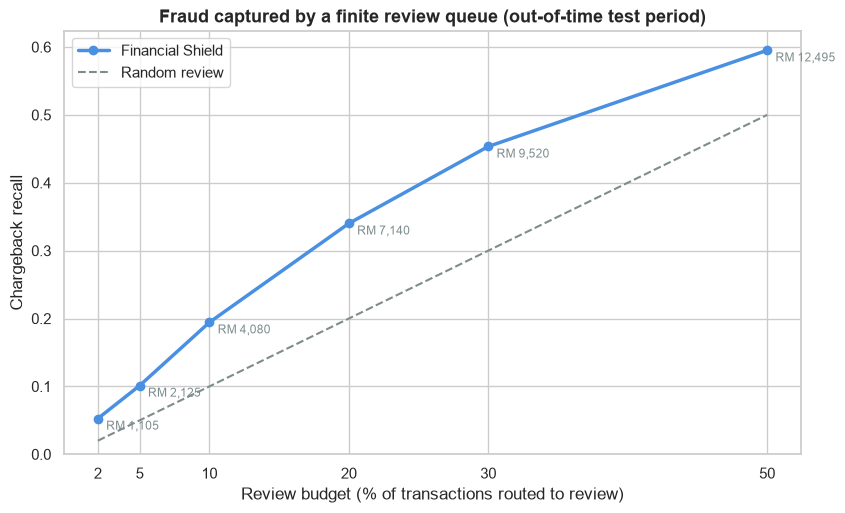

Capacity mode (top 10%) economics (test period):
  Chargebacks caught      : 48 of 247 -> potential RM 4,080 prevented
  Chargebacks missed      : 199 -> potential RM 16,915 still exposed
  Legitimate txns flagged : 792 (manual-review load)
  Reviews per chargeback  : 17.5

High-recall mode (validation target 90%) economics (test period):
  Chargebacks caught      : 226 of 247 -> potential RM 19,210 prevented
  Chargebacks missed      : 21 -> potential RM 1,785 still exposed
  Legitimate txns flagged : 7,105 (manual-review load)
  Reviews per chargeback  : 32.4


In [24]:
ranked = np.argsort(-p_test, kind="mergesort")
n_test = len(y_test)
n_chargebacks_test = int(y_test.sum())
review_budgets = (0.02, 0.05, 0.10, 0.20, 0.30, 0.50)

budget_rows = []
for budget in review_budgets:
    reviewed = max(1, int(np.ceil(n_test * budget)))
    caught = int(y_test[ranked[:reviewed]].sum())
    precision = caught / reviewed
    budget_rows.append({
        "Review budget": f"top {budget:.0%} of transactions",
        "Transactions reviewed": reviewed,
        "Chargebacks caught": f"{caught} / {n_chargebacks_test}",
        "Recall": caught / max(n_chargebacks_test, 1),
        "Precision": precision,
        "Lift vs random": precision / max(y_test.mean(), 1e-12),
        "Reviews per chargeback": reviewed / max(caught, 1),
        "Potential RM loss prevented": f"RM {caught * RM_PER_CHARGEBACK:,}",
    })
budget_table = pd.DataFrame(budget_rows)
display(budget_table)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
budgets_pct = [100 * budget for budget in review_budgets]
recalls_at_budget = [row["Recall"] for row in budget_rows]
ax.plot(budgets_pct, recalls_at_budget, marker="o", color=BLUE, lw=2.5, label="Financial Shield")
ax.plot(budgets_pct, review_budgets, color=GREY, ls="--", label="Random review")
for budget_pct, recall, row in zip(budgets_pct, recalls_at_budget, budget_rows):
    ax.annotate(
        row["Potential RM loss prevented"],
        (budget_pct, recall),
        textcoords="offset points", xytext=(6, -8), fontsize=8.5, color=GREY,
    )
ax.set_xlabel("Review budget (% of transactions routed to review)")
ax.set_ylabel("Chargeback recall")
ax.set_title("Fraud captured by a finite review queue (out-of-time test period)")
ax.set_xticks(budgets_pct)
ax.set_ylim(bottom=0)
ax.legend()
plt.show()


def print_economics(label, confusion):
    true_positive, false_negative = confusion[1, 1], confusion[1, 0]
    false_positive = confusion[0, 1]
    print(f"{label} economics (test period):")
    print(
        f"  Chargebacks caught      : {true_positive} of {true_positive + false_negative} "
        f"-> potential RM {true_positive * RM_PER_CHARGEBACK:,} prevented"
    )
    print(f"  Chargebacks missed      : {false_negative} -> potential RM {false_negative * RM_PER_CHARGEBACK:,} still exposed")
    print(f"  Legitimate txns flagged : {false_positive:,} (manual-review load)")
    print(f"  Reviews per chargeback  : {(true_positive + false_positive) / max(true_positive, 1):.1f}")


print_economics(f"Capacity mode (top {REVIEW_BUDGET_FRACTION:.0%})", cm_capacity)
print()
print_economics(f"High-recall mode (validation target {TARGET_RECALL:.0%})", cm_high_recall)


### 9. Final strategic verdict & deployment recommendation

#### What the Financial Shield is
A **risk-ranking and triage tool**, evaluated on a future out-of-time period. Its practical value is whether it concentrates chargebacks in the portion of the queue that operations can review, not whether it posts an attractive accuracy number.

#### What it is not
It is not a justification for automatic declines. With a rare positive class and limited behavioural signal, a high-recall policy can still flag many legitimate customers. Raw model scores are also not approved as literal probabilities without a separate calibration process.

#### Recommended deployment path
1. **Start with a fixed-capacity human-review queue.** Set `REVIEW_BUDGET_FRACTION` from actual staffing, review the riskiest orders, and measure realised outcomes.
2. **Use validation thresholds only as policy scenarios.** The max-F1 and high-recall modes show the recall / workload trade-off; they are not automatic business decisions.
3. **Monitor out-of-time performance.** Track queue precision, recall once labels mature, score distribution, chargeback rate, category drift, and intervention success each month.
4. **Calibrate only on fresh labelled data.** If a downstream system needs probabilities, reserve a calibration set after model selection and validate reliability again on future data.
5. **Improve the data before making the model larger.** Add verified payment / address links, device fingerprints, prior reviewed outcomes, velocity features, and review disposition labels.

#### Limitations and governance
* Customer history is causal but only as complete as the transaction stream supplied at scoring time. Missing or delayed history would reduce performance.
* The latest 20% test estimate is intentionally used once; it is an honest estimate, not a continually tuned leaderboard.
* Permutation importance identifies predictive association, not causal reason. Check for bias, policy feedback loops, and feature availability before deployment.
* Potential RM prevented assumes successful human intervention and excludes review cost and customer friction. A live pilot should measure both.
* Re-run this notebook when the feature schema changes or a new labelled period arrives; record the exact data window, configuration, and resulting metrics.
